# Clase 3 - BER de LoRa en canal selectivo

**Objetivo.** Partir de un chirp LoRa ideal, aplicarle el canal selectivo del artículo y medir cómo el ruido afecta la BER. Las funciones de procesamiento por lotes se escriben aquí —en lugar de ocultarlas en `src`— para que cada paso de la simulación pueda leerse y relacionarse con su ecuación. Los símbolos y el ruido se generan sin semilla fija, por lo que cada ejecución produce una realización distinta.

In [40]:
from pathlib import Path
import sys

from matplotlib.axes import Axes
import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import (
    agregar_ruido_awgn,
    calc_error,
    demodular_simbolo,
    modular_simbolo,
    parametros_ruido_desde_snr,
)


## 1. Repaso: un símbolo ideal

**Objetivo.** Verificar el caso base antes de introducir canal y ruido. Con `SF=7`, cada símbolo representa 7 bits y tiene `N=128` muestras. Modulamos un entero, aplicamos dechirp y FFT, y comprobamos que el símbolo detectado y la BER sean correctos en el canal ideal.

In [41]:
SF = 7
N = 2**SF
B = 125_000  # Hz
Ts = N / B
generador_repaso = np.random.default_rng()

enviado = int(generador_repaso.integers(N))
chirp = modular_simbolo(enviado, np.arange(N), N)
estimado, _, espectro_ideal = demodular_simbolo(chirp)
ber_ideal = calc_error([enviado], [estimado], bits_por_simbolo=SF)

assert estimado == enviado and ber_ideal == 0
print(f'SF={SF}, N={N}, Ts={Ts * 1e3:.3f} ms')
print(f'Enviado: {enviado:0{SF}b}; detectado: {estimado:0{SF}b}; BER={ber_ideal:.1f}')


SF=7, N=128, Ts=1.024 ms
Enviado: 0111101; detectado: 0111101; BER=0.0


## 2. Chirp discreto según el artículo

**Objetivo.** Usar únicamente el modelo discreto del artículo. La ecuación (3) define el chirp para `k=0,…,N−1`, por lo que los primeros dos paneles muestran sus componentes real e imaginaria en esas `N` muestras. El tercero muestra el índice $[(s+k) mod N]B/N$ que aparece en la ecuación, sin extender la señal a tiempo continuo. El último panel muestra la energía después de dechirp y FFT: su máximo indica el símbolo detectado.

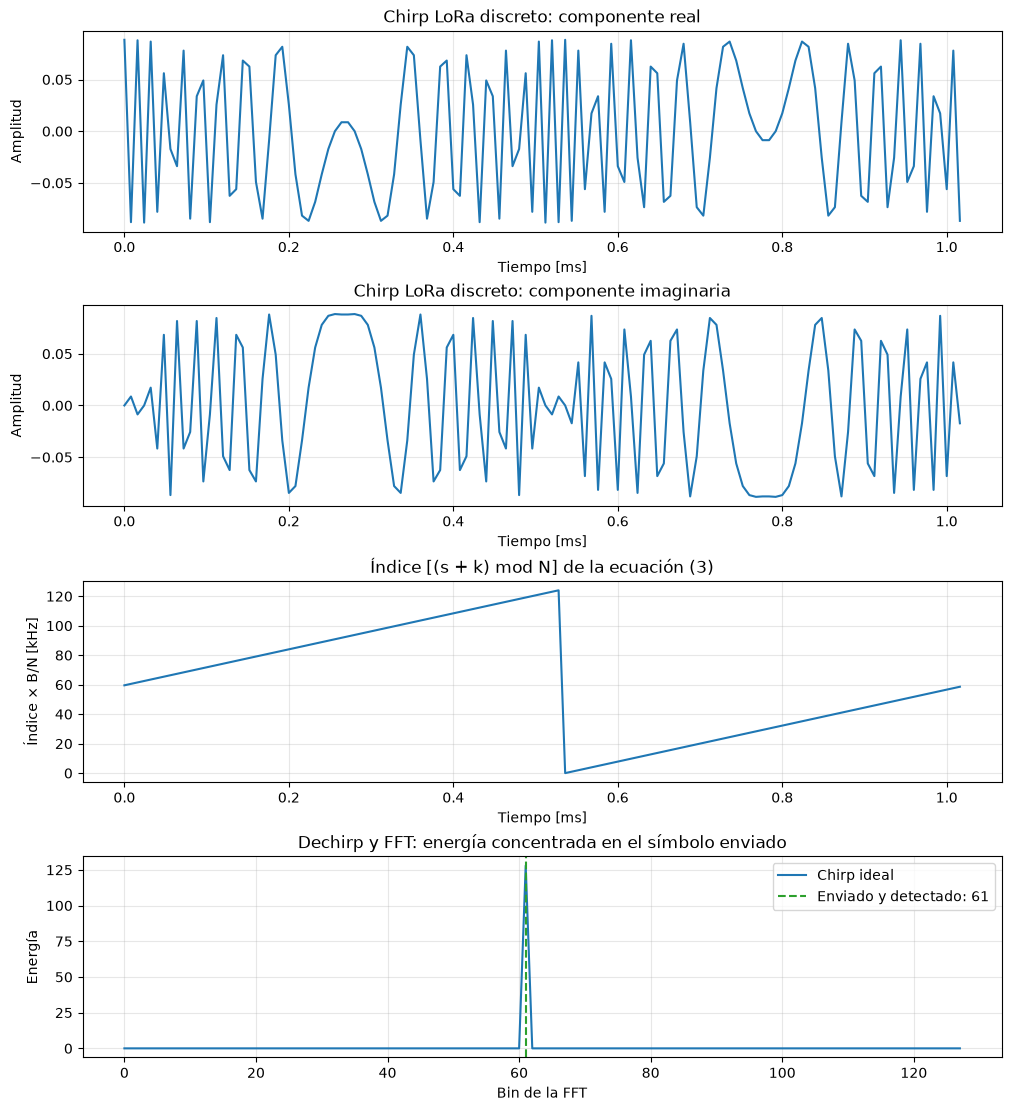

In [42]:
def graficar_curvas(
    tiempo: np.ndarray,
    curvas: list[tuple[str, np.ndarray]],
    *,
    titulo: str,
    etiqueta_y: str,
    ax: Axes | None = None,
) -> Axes:
    """Grafica curvas temporales con el formato común de este notebook."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    for etiqueta, valores in curvas:
        ax.plot(tiempo * 1e3, valores, label=etiqueta)
    ax.set(title=titulo, xlabel='Tiempo [ms]', ylabel=etiqueta_y)
    ax.grid(True, alpha=0.3)
    if len(curvas) > 1:
        ax.legend()
    return ax

def graficar_energia_espectral(
    espectros: list[tuple[str, np.ndarray]],
    *, enviado: int, detectado: int, titulo: str, ax: Axes
) -> Axes:
    """Muestra la energía de la FFT y los bins relevantes para decidir."""
    bins = np.arange(N)
    for etiqueta, espectro in espectros:
        ax.plot(bins, np.abs(espectro)**2, label=etiqueta)
    if enviado == detectado:
        ax.axvline(enviado, color='tab:green', linestyle='--', label=f'Enviado y detectado: {enviado}')
    else:
        ax.axvline(enviado, color='tab:green', linestyle='--', label=f'Enviado: {enviado}')
        ax.axvline(detectado, color='tab:red', linestyle=':', label=f'Detectado: {detectado}')
    ax.set(title=titulo, xlabel='Bin de la FFT', ylabel='Energía')
    ax.grid(True, alpha=0.3)
    ax.legend()
    return ax

k = np.arange(N)
tiempo_discreto = k / B
indice_ecuacion = np.mod(enviado + k, N) * B / N

fig, axes = plt.subplots(4, 1, figsize=(10, 11), constrained_layout=True)
graficar_curvas(
    tiempo_discreto, [('Muestras del chirp', chirp.real)],
    titulo='Chirp LoRa discreto: componente real', etiqueta_y='Amplitud', ax=axes[0]
)
graficar_curvas(
    tiempo_discreto, [('Muestras del chirp', chirp.imag)],
    titulo='Chirp LoRa discreto: componente imaginaria', etiqueta_y='Amplitud', ax=axes[1]
)
graficar_curvas(
    tiempo_discreto, [('Índice de la ecuación (3)', indice_ecuacion / 1e3)],
    titulo='Índice [(s + k) mod N] de la ecuación (3)', etiqueta_y='Índice × B/N [kHz]', ax=axes[2]
)
graficar_energia_espectral(
    [('Chirp ideal', espectro_ideal)], enviado=enviado, detectado=estimado,
    titulo='Dechirp y FFT: energía concentrada en el símbolo enviado', ax=axes[3]
)
plt.show()


## 3. Canal FIR y procesamiento por lotes

**Objetivo.** Construir el canal selectivo y el único motor reutilizable de simulación. En esta primera celda se definen y verifican las herramientas: el FIR, la modulación y detección por lotes, y `simular_lote`. Las partes 4, 5 y 6 sólo cambiarán cuántos símbolos le piden a ese motor. El siguiente bloque usa esas herramientas para visualizar qué hace el FIR sobre un chirp.

In [43]:
def aplicar_canal_fir(senal: np.ndarray, respuesta_impulsional: np.ndarray) -> np.ndarray:
    # y[k] = sum_m h[m] x[k-m]; np.convolve devuelve también la cola del filtro.
    return np.convolve(senal, respuesta_impulsional)

def modular_trama(valores: np.ndarray) -> np.ndarray:
    # Cada fila corresponde a un símbolo; el broadcasting evalúa todos los chirps juntos.
    k = np.arange(N)
    fase = ((valores[:, None] + k) % N) * k / N
    return np.exp(1j * 2 * np.pi * fase) / np.sqrt(N)

def demodular_trama(recibidas: np.ndarray) -> np.ndarray:
    # El mismo downchirp se multiplica por cada fila y la FFT se calcula sobre axis=1.
    k = np.arange(N)
    downchirp = np.exp(-1j * 2 * np.pi * k**2 / N)
    espectros = np.fft.fft(recibidas * downchirp, axis=1)
    return np.argmax(np.abs(espectros)**2, axis=1)

# Canal del artículo: su energía es uno, así que no amplifica la señal en promedio.
h = np.array([np.sqrt(0.8), np.sqrt(0.2)])
assert np.isclose(np.sum(np.abs(h)**2), 1.0)
impulso = np.r_[1.0, np.zeros(N - 1)]
np.testing.assert_allclose(aplicar_canal_fir(impulso, h)[:len(h)], h)

def simular_lote(
    snr_db: float,
    cantidad_simbolos: int,
    generador: np.random.Generator,
    respuesta_impulsional: np.ndarray = h,
    retardo_canal: int = 0,
):
    """Simula símbolos aleatorios: chirp, FIR, AWGN y detección."""
    enviados = generador.integers(0, N, cantidad_simbolos)
    transmitida = modular_trama(enviados)
    # Se concatena la trama para que la memoria del FIR pase de un símbolo al siguiente.
    salida_completa = aplicar_canal_fir(transmitida.ravel(), respuesta_impulsional)
    # Un delta centrado sólo retrasa; se alinea antes de separar nuevamente los símbolos.
    filtrada = salida_completa[retardo_canal:retardo_canal + transmitida.size]
    limpia = filtrada.reshape(cantidad_simbolos, N)
    potencia_senal = float(np.mean(np.abs(transmitida)**2))
    _, sigma = parametros_ruido_desde_snr(snr_db, potencia_senal)
    # El ruido se suma después del FIR para conservar AWGN blanco en el receptor.
    recibida, ruido = agregar_ruido_awgn(limpia, sigma, generador)
    estimados = demodular_trama(recibida)
    return enviados, estimados, limpia, recibida, ruido, potencia_senal, sigma

# Control sin ruido: el mismo motor conserva todos los símbolos del alfabeto.
control = np.arange(N)
control_limpio = aplicar_canal_fir(modular_trama(control).ravel(), h)[:N*N].reshape(N, N)
assert calc_error(control, demodular_trama(control_limpio), bits_por_simbolo=SF) == 0




### 3.1 Visualizar el efecto del canal

**Objetivo.** Usar las herramientas anteriores para observar el FIR sin mezclar esta demostración con su definición. El primer panel es la respuesta impulsional $h[k]$; el segundo compara las muestras reales antes y después del filtro; el tercero muestra la energía de la señal tras dechirp y FFT. Todo el cálculo es discreto.

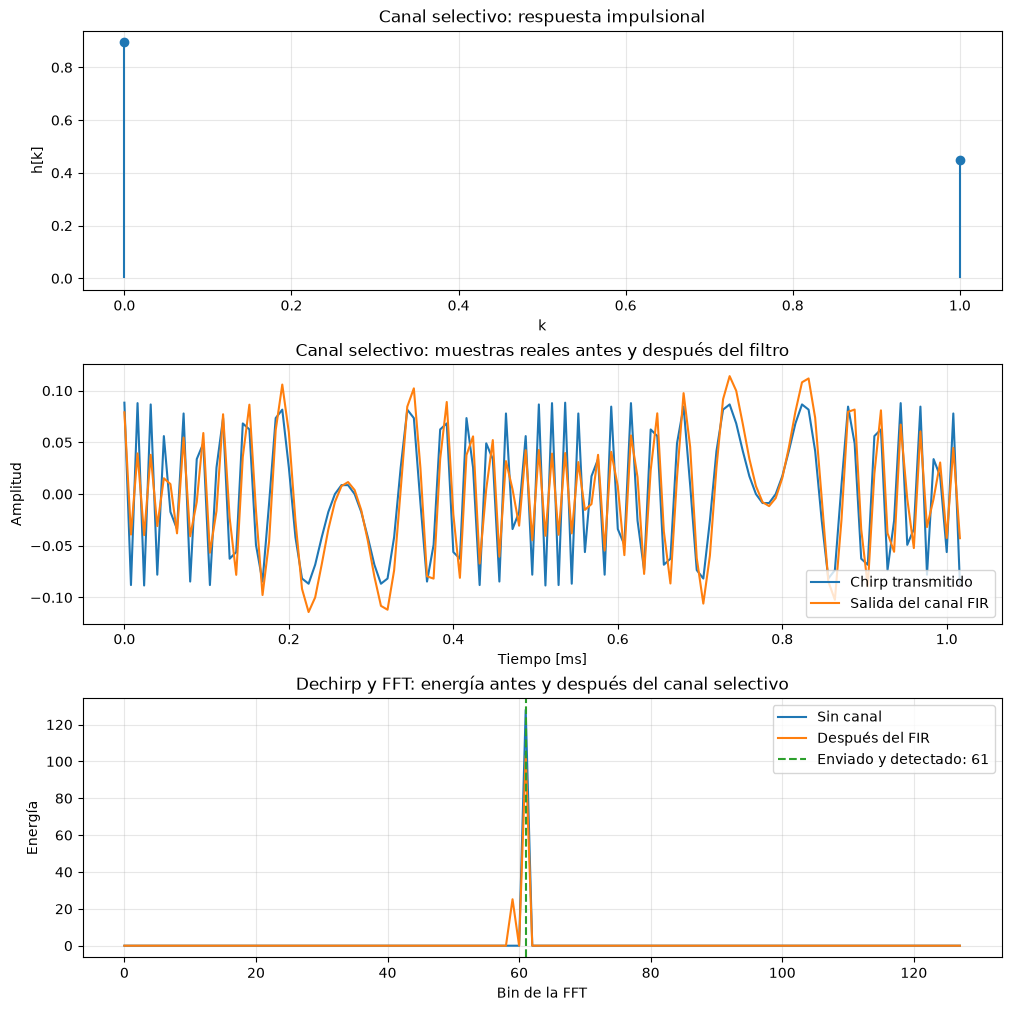

In [44]:
# Esta es la convolución discreta que recibe y demodula el receptor.
salida_discreta = aplicar_canal_fir(chirp, h)[:N]
detectado_canal, _, espectro_canal = demodular_simbolo(salida_discreta)
_, _, espectro_sin_canal = demodular_simbolo(chirp)
assert detectado_canal == enviado

fig, axes = plt.subplots(3, 1, figsize=(10, 10), constrained_layout=True)
axes[0].stem(np.arange(len(h)), h, basefmt=' ')
axes[0].set(title='Canal selectivo: respuesta impulsional', xlabel='k', ylabel='h[k]')
axes[0].grid(True, alpha=0.3)
graficar_curvas(
    tiempo_discreto,
    [('Chirp transmitido', chirp.real), ('Salida del canal FIR', salida_discreta.real)],
    titulo='Canal selectivo: muestras reales antes y después del filtro',
    etiqueta_y='Amplitud', ax=axes[1]
)
graficar_energia_espectral(
    [('Sin canal', espectro_sin_canal), ('Después del FIR', espectro_canal)],
    enviado=enviado, detectado=detectado_canal,
    titulo='Dechirp y FFT: energía antes y después del canal selectivo', ax=axes[2]
)
plt.show()


## 4. ¿Dónde se agrega el ruido?

**Objetivo.** Mostrar el orden físico del canal y una realización que produce un error. Primero se calcula $y=c*h$ mediante convolución y luego se suma AWGN: $r=y+w$. Así el ruido es blanco en la entrada del receptor; si se agregara antes, el FIR lo colorearía y sería otro canal. Buscamos una realización con error: el panel superior muestra sus muestras reales y el inferior compara las energías de las FFT luego de dechirp. Las líneas verticales indican el bin enviado y el que ganó la detección.

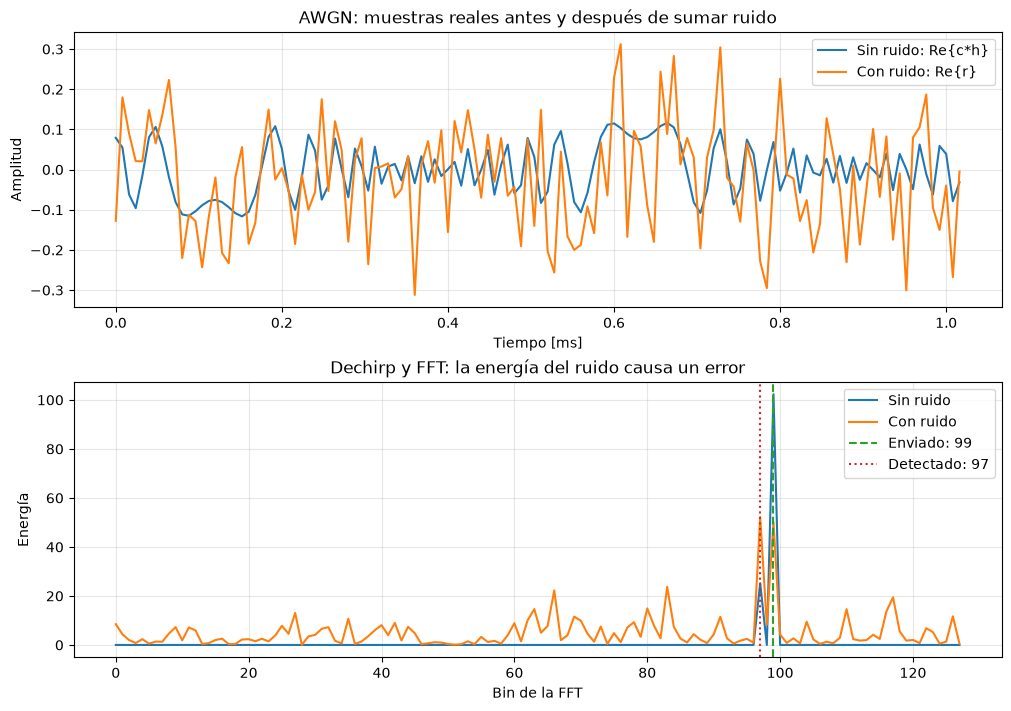

SNR=-7 dB | enviado=1100011 | detectado=1100001


In [45]:
generador_error = np.random.default_rng()
SNR_ERROR_DB = -7
for _ in range(500):
    enviados_error, estimados_error, limpias, recibidas, _, _, _ = simular_lote(
        SNR_ERROR_DB, 1, generador_error
    )
    valor_error = int(enviados_error[0])
    detectado_error = int(estimados_error[0])
    if detectado_error != valor_error: # encontré un error
        limpia, ruidosa = limpias[0], recibidas[0]
        break
else:
    raise RuntimeError('No se encontró un error; probá una SNR menor')

_, _, espectro_limpio = demodular_simbolo(limpia)
_, _, espectro_ruidoso = demodular_simbolo(ruidosa)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
graficar_curvas(
    tiempo_discreto,
    [('Sin ruido: Re{c*h}', limpia.real), ('Con ruido: Re{r}', ruidosa.real)],
    titulo='AWGN: muestras reales antes y después de sumar ruido',
    etiqueta_y='Amplitud', ax=axes[0]
)
graficar_energia_espectral(
    [('Sin ruido', espectro_limpio), ('Con ruido', espectro_ruidoso)],
    enviado=valor_error, detectado=detectado_error,
    titulo='Dechirp y FFT: la energía del ruido causa un error', ax=axes[1]
)
plt.show()
print(f'SNR={SNR_ERROR_DB} dB | enviado={valor_error:0{SF}b} | detectado={detectado_error:0{SF}b}')


## 5. BER en una SNR

**Objetivo.** Obtener una estimación puntual de BER antes del barrido. Reutilizamos `simular_lote` con 10.000 símbolos aleatorios: no se crea otro canal ni otra cadena de recepción. `calc_error(..., bits_por_simbolo=SF)` compara los 7 bits de cada entero sin convertir miles de símbolos a texto. Aquí alcanza con reportar potencia, errores y BER; la visualización de un error ya quedó explicada en la parte 4.

In [46]:
SNR_EJEMPLO_DB = -15
generador_ejemplo = np.random.default_rng()
enviados, estimados, _, _, ruido, potencia_senal, sigma = simular_lote(
    SNR_EJEMPLO_DB, 10_000, generador_ejemplo
)
ber_ejemplo = calc_error(enviados, estimados, bits_por_simbolo=SF)
bits_comparados = len(enviados) * SF
errores = round(ber_ejemplo * bits_comparados)
print(f'SNR={SNR_EJEMPLO_DB} dB | BER={ber_ejemplo:.3e} ({errores} errores sobre {bits_comparados} bits)')
print(f'Potencia señal={potencia_senal:.6f}; potencia ruido medida={np.mean(np.abs(ruido)**2):.6f}; sigma={sigma:.6f}')


SNR=-15 dB | BER=3.450e-01 (24148 errores sobre 70000 bits)
Potencia señal=0.007812; potencia ruido medida=0.246628; sigma=0.497044


## 6. Curva BER Monte Carlo

**Objetivo.** Repetir la medición de la parte 5 para cada SNR entre −9 y −3 dB. `estimar_ber` no crea otro modelo: llama varias veces a `simular_lote` hasta acumular 100 errores de bit o alcanzar 250.000 símbolos. El segundo límite evita que la simulación se vuelva innecesariamente lenta cuando la BER es muy baja; por eso cada fila reporta símbolos, bits y errores junto a su BER. Como los símbolos y el ruido son nuevos en cada ejecución, la curva tendrá pequeñas variaciones estadísticas. La comparación con el canal plano se grafica al final, en la parte 7.

In [47]:
def estimar_ber(
    snr_db: float,
    respuesta_impulsional: np.ndarray = h,
    retardo_canal: int = 0,
) -> tuple[int, int, int, float]:
    generador = np.random.default_rng()
    errores_totales = bits_totales = simbolos_totales = 0
    while errores_totales < 100 and simbolos_totales < 250_000:
        cantidad = min(10_000, 250_000 - simbolos_totales)
        enviados, estimados, _, _, _, _, _ = simular_lote(
            snr_db, cantidad, generador, respuesta_impulsional, retardo_canal
        )
        ber_lote = calc_error(enviados, estimados, bits_por_simbolo=SF)
        bits_lote = cantidad * SF
        # BER por cantidad de bits recupera el entero de errores de este lote.
        errores_totales += round(ber_lote * bits_lote)
        bits_totales += bits_lote
        simbolos_totales += cantidad
    return simbolos_totales, bits_totales, errores_totales, errores_totales / bits_totales

snr_db = np.arange(-9, -2, 1)
resultados = [estimar_ber(snr) for snr in snr_db]
ber = np.array([resultado[-1] for resultado in resultados])
for snr, (simbolos, bits, errores, valor_ber) in zip(snr_db, resultados):
    print(f'SNR={snr:>3} dB | símbolos={simbolos:>6} | bits={bits:>7} | errores={errores:>4} | BER={valor_ber:.3e}')



SNR= -9 dB | símbolos= 10000 | bits=  70000 | errores=1623 | BER=2.319e-02
SNR= -8 dB | símbolos= 10000 | bits=  70000 | errores= 695 | BER=9.929e-03
SNR= -7 dB | símbolos= 10000 | bits=  70000 | errores= 288 | BER=4.114e-03
SNR= -6 dB | símbolos= 10000 | bits=  70000 | errores= 135 | BER=1.929e-03
SNR= -5 dB | símbolos= 30000 | bits= 210000 | errores= 139 | BER=6.619e-04
SNR= -4 dB | símbolos= 80000 | bits= 560000 | errores= 102 | BER=1.821e-04
SNR= -3 dB | símbolos=250000 | bits=1750000 | errores=  70 | BER=4.000e-05


## 7. Curva BER Monte Carlo: comparación con canal plano

**Objetivo.** Repetir el barrido con un canal plano y compararlo en la misma figura con el canal selectivo. Su respuesta impulsional es $h_{\mathrm{plano}}[k]=\delta[k]=[1]$: la convolución deja la señal intacta, sin retardo ni distorsión. El canal plano se barre desde −10 dB, igual que el rango visible de comparación. Cada punto dibujado muestra también su BER en notación científica para compararla con la Fig. 1. Si un punto no observa errores, se informa BER cero en la tabla y se omite del gráfico, porque la escala logarítmica no puede representar cero.

SNR=-10 dB | símbolos= 10000 | bits=  70000 | errores=1377 | BER=1.967e-02
SNR= -9 dB | símbolos= 10000 | bits=  70000 | errores= 350 | BER=5.000e-03
SNR= -8 dB | símbolos= 30000 | bits= 210000 | errores= 126 | BER=6.000e-04
SNR= -7 dB | símbolos=220000 | bits=1540000 | errores= 100 | BER=6.494e-05
SNR= -6 dB | símbolos=250000 | bits=1750000 | errores=   9 | BER=5.143e-06
SNR= -5 dB | símbolos=250000 | bits=1750000 | errores=   0 | BER=0.000e+00
SNR= -4 dB | símbolos=250000 | bits=1750000 | errores=   0 | BER=0.000e+00
SNR= -3 dB | símbolos=250000 | bits=1750000 | errores=   0 | BER=0.000e+00


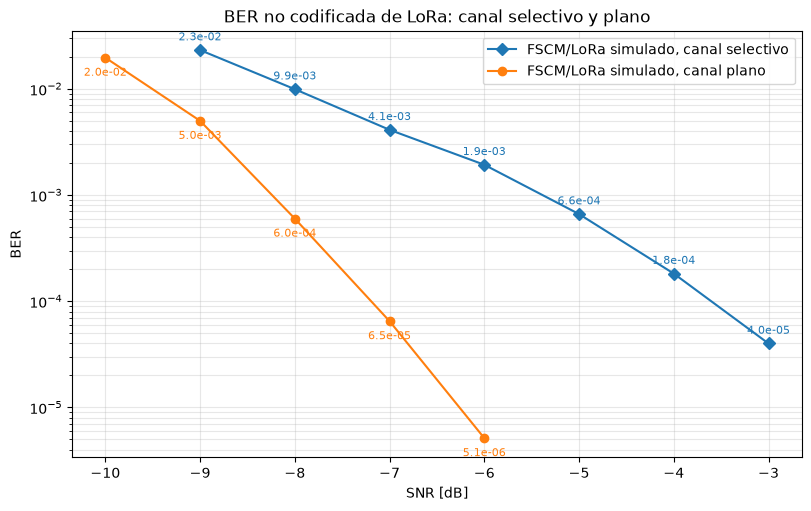

In [48]:
# Delta en k=0: canal plano, sin retardo ni distorsión.
h_plano = np.array([1.0])
retardo_plano = 0
assert np.isclose(np.sum(np.abs(h_plano)**2), 1.0)

# Sin ruido, el canal plano no cambia ningún símbolo.
control_transmitida = modular_trama(control).ravel()
control_plano = aplicar_canal_fir(control_transmitida, h_plano)
control_plano = control_plano[retardo_plano:retardo_plano + control_transmitida.size]
control_plano = control_plano.reshape(N, N)
assert calc_error(control, demodular_trama(control_plano), bits_por_simbolo=SF) == 0

snr_db_plano = np.arange(-10, -2, 1)
resultados_plano = [
    estimar_ber(snr, h_plano, retardo_plano) for snr in snr_db_plano
]
ber_plano = np.array([resultado[-1] for resultado in resultados_plano])
for snr, (simbolos, bits, errores, valor_ber) in zip(snr_db_plano, resultados_plano):
    print(f'SNR={snr:>3} dB | símbolos={simbolos:>6} | bits={bits:>7} | errores={errores:>4} | BER={valor_ber:.3e}')

# Logaritmo de cero no existe: esos puntos se informan en la tabla, no se dibujan.
mascara_plano = ber_plano > 0
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.semilogy(snr_db, ber, 'D-', label='FSCM/LoRa simulado, canal selectivo')
ax.semilogy(
    snr_db_plano[mascara_plano], ber_plano[mascara_plano], 'o-',
    label='FSCM/LoRa simulado, canal plano',
)
for snr, valor_ber in zip(snr_db, ber):
    ax.annotate(f'{valor_ber:.1e}', (snr, valor_ber), xytext=(0, 7),
                textcoords='offset points', ha='center', fontsize=8, color='C0')
for snr, valor_ber in zip(snr_db_plano[mascara_plano], ber_plano[mascara_plano]):
    ax.annotate(f'{valor_ber:.1e}', (snr, valor_ber), xytext=(0, -13),
                textcoords='offset points', ha='center', fontsize=8, color='C1')
ax.set(title='BER no codificada de LoRa: canal selectivo y plano', xlabel='SNR [dB]', ylabel='BER')
ax.set_xticks(np.arange(-10, -2, 1))
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.show()


## Conclusión

La simulación discreta sigue siempre la cadena `símbolo → chirp → convolución FIR → AWGN → dechirp/FFT → BER`. Las curvas finales reutilizan esa misma cadena: una usa el canal selectivo del artículo y la otra el impulso unitario del canal plano. Las visualizaciones también se obtienen de las `N` muestras definidas por la ecuación (3).